# Medium and Substack scored posts

Looking at the two annual 50k files with detector scores on them:

- `medium_analysis_full_annual_50k_scored_with_date.csv`
- `substack_analysis_full_annual_50k_scored_with_date.csv`

Each row is one post. Publication dates use `YYYY-MM-DD`, such as `2020-01-15`, with no time or timezone component. Monthly plots group these dates by `YYYY-MM`. The source window is January 2020 through 17 September 2026; September 2026 is a partial month. We treat December 2022 as the break (first full month after ChatGPT).

`P_AI` and `P_HUMAN` sum to 1. The OpenAI / Anthropic / Gemini / Other columns split the AI mass. `PREDICTION` is just whichever of those four wins, even when the post looks human — so for "which model" we lean on the `*_GIVEN_AI` columns, or we restrict to posts where `P_AI` is high.


In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

plt.rcParams.update({
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "font.size": 11,
})

# Find the enclosing project from the project root, checkout, or notebooks folder.
ROOT = next(
    (p for p in (Path.cwd(), *Path.cwd().parents)
     if (p / "research" / "PROJECT_CONTEXT.md").is_file()),
    None,
)
if ROOT is None:
    raise FileNotFoundError("Run this notebook from inside the local capstone project folder.")
DATA_PATHS = {
    "medium": ROOT / "outputs" / "medium_sampling_2026-10-14" / "medium_analysis_full_annual_50k_scored_with_date.csv",
    "substack": ROOT / "outputs" / "substack-sampled-final-2026-10-02" / "substack_analysis_full_annual_50k_scored_with_date.csv",
}
CUT = "2022-12"
P_COLS = ["P_OPENAI", "P_ANTHROPIC", "P_GEMINI", "P_OTHER"]
GIVEN = {
    "P_OPENAI_GIVEN_AI": "OpenAI",
    "P_ANTHROPIC_GIVEN_AI": "Anthropic",
    "P_GEMINI_GIVEN_AI": "Gemini",
    "P_OTHER_GIVEN_AI": "Other",
}
GIVEN_COLS = list(GIVEN)
FAM_COLORS = {
    "OpenAI": "#c45c26",
    "Anthropic": "#1b3a4b",
    "Gemini": "#2f6f5e",
    "Other": "#8a8790",
}

def load(path):
    df = pd.read_csv(path, dtype={"published_date": "string"})
    # The date-only CSVs use one exact format; retain YYYY-MM-DD strings.
    valid_date = df["published_date"].str.fullmatch(r"[0-9]{4}-[0-9]{2}-[0-9]{2}", na=False)
    if not valid_date.all():
        raise ValueError(f"{path.name} contains missing or invalid publication dates.")
    dates = pd.to_datetime(df["published_date"], format="%Y-%m-%d", errors="raise")
    df["year_month"] = df["published_date"].str[:7]
    df["year"] = dates.dt.year
    df["month"] = dates.dt.month
    df["period"] = np.where(df["year_month"] >= CUT, "post", "pre")
    df["ai_05"] = df["P_AI"] >= 0.5
    df["ai_08"] = df["P_AI"] >= 0.8
    df["ai_95"] = df["P_AI"] >= 0.95
    return df

medium = load(DATA_PATHS["medium"])
substack = load(DATA_PATHS["substack"])
# All publication dates are validated above; every post stays in the analysis.
m = medium.copy()
s = substack.copy()

print(f"medium: {len(medium):,} rows, {medium.post_id.nunique():,} unique, {medium.published_date.isna().sum():,} missing dates")
print(f"substack: {len(substack):,} rows, {substack.post_id.nunique():,} unique, {substack.published_date.isna().sum():,} missing dates")
print("columns:", list(medium.columns[:19]))


medium: 350,000 rows, 350,000 unique, 0 missing dates
substack: 350,000 rows, 350,000 unique, 0 missing dates
columns: ['platform', 'post_id', 'word_count_source', 'topic_code', 'creator_count', 'PREDICTION', 'PREDICTION_SCORE', 'P_AI', 'P_HUMAN', 'P_OPENAI', 'P_ANTHROPIC', 'P_GEMINI', 'P_OTHER', 'P_OPENAI_GIVEN_AI', 'P_ANTHROPIC_GIVEN_AI', 'P_GEMINI_GIVEN_AI', 'P_OTHER_GIVEN_AI', 'DETECTOR_TOKENS_USED', 'published_date']


## Quick look at the files

Both date-only CSVs contain the same detector columns and exactly 50,000 posts per year. `published_date` contains only year, month and day (`YYYY-MM-DD`). The notebook validates that exact format and retains the day while deriving `year_month` for monthly plots and the December 2022 comparison.

All 350,000 posts per platform have valid publication dates. The original `_scored_with_time.csv` files preserve the complete source timestamps. The date-only copies preserve every other field and row order. September 2026 remains partial through September 17.


In [2]:
def inventory(df, label):
    return {
        "platform": label,
        "rows": len(df),
        "unique posts": df["post_id"].nunique(),
        "missing dates": int(df["published_date"].isna().sum()),
        "first date": df["published_date"].min(),
        "last date": df["published_date"].max(),
        "mean P_AI": round(df["P_AI"].mean(), 4),
        "median P_AI": round(df["P_AI"].median(), 4),
        "share ≥0.5": round(df["ai_05"].mean(), 4),
        "median words": int(df["word_count_source"].median()),
        "topics": sorted(df["topic_code"].dropna().unique().tolist()),
    }

display(pd.DataFrame([inventory(medium, "medium"), inventory(substack, "substack")]))

by_year = pd.concat({
    "medium": m.groupby("year").size(),
    "substack": s.groupby("year").size(),
}, axis=1)
display(by_year.astype("Int64"))


,platform,rows,unique posts,missing dates,first date,last date,mean P_AI,median P_AI,share ≥0.5,median words,topics
0,medium,350000,350000,0,2020-01-01,2026-09-17,0.3686,0.0009,0.3686,654,"[0, 1, 2, 3, 4, 5, 6, 7, 8]"
1,substack,350000,350000,0,2020-01-01,2026-09-17,0.1063,0.0005,0.1058,832,"[0, 1, 2, 3, 4, 5, 6, 7, 8, 9]"


,medium,substack
year,,
2020,50000,50000
2021,50000,50000
2022,50000,50000
2023,50000,50000
2024,50000,50000
2025,50000,50000
2026,50000,50000


## How the scores fit together

Sanity check first. Then a note on `PREDICTION`: it still names an AI family when the post looks human.


,platform,mean(P_AI+P_HUMAN),max |P_AI − family sum|,PREDICTION labels
0,medium,1.0,1.450526e-07,4
1,substack,1.0,1.430399e-07,4


PREDICTION when P_HUMAN ≥ 0.9 (medium)
PREDICTION
Other        172631
OpenAI        42104
Gemini         1492
Anthropic      1129

PREDICTION when P_AI ≥ 0.5 (medium)
PREDICTION
OpenAI       72176
Other        41048
Anthropic    10662
Gemini        5132

PREDICTION when P_AI ≥ 0.5 (substack)
PREDICTION
Other        17098
OpenAI       13200
Anthropic     4894
Gemini        1833


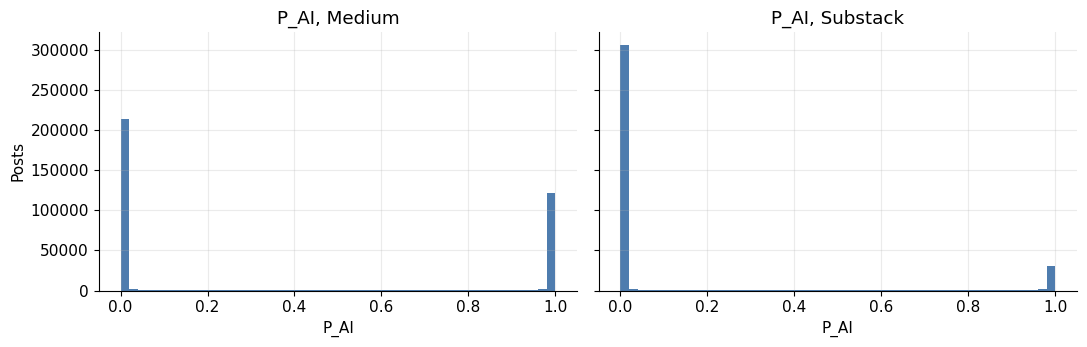

In [3]:
def score_bits(df, label):
    fam = df[P_COLS].sum(axis=1)
    return pd.Series({
        "platform": label,
        "mean(P_AI+P_HUMAN)": (df["P_AI"] + df["P_HUMAN"]).mean(),
        "max |P_AI − family sum|": (df["P_AI"] - fam).abs().max(),
        "PREDICTION labels": df["PREDICTION"].nunique(),
    })

display(pd.DataFrame([score_bits(medium, "medium"), score_bits(substack, "substack")]))

print("PREDICTION when P_HUMAN ≥ 0.9 (medium)")
print(medium.loc[medium.P_HUMAN >= 0.9, "PREDICTION"].value_counts().to_string())
print("\nPREDICTION when P_AI ≥ 0.5 (medium)")
print(medium.loc[medium.ai_05, "PREDICTION"].value_counts().to_string())
print("\nPREDICTION when P_AI ≥ 0.5 (substack)")
print(substack.loc[substack.ai_05, "PREDICTION"].value_counts().to_string())

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True)
for ax, df, title in [(axes[0], medium, "Medium"), (axes[1], substack, "Substack")]:
    ax.hist(df["P_AI"], bins=50, color="#3b6ea5", alpha=0.9)
    ax.set_title(f"P_AI, {title}")
    ax.set_xlabel("P_AI")
axes[0].set_ylabel("Posts")
fig.tight_layout()
plt.show()


## AI score month by month

Main plot for the project. Mean `P_AI`, share above 0.5, and a 3-month rolling mean so the line is a bit less jumpy.


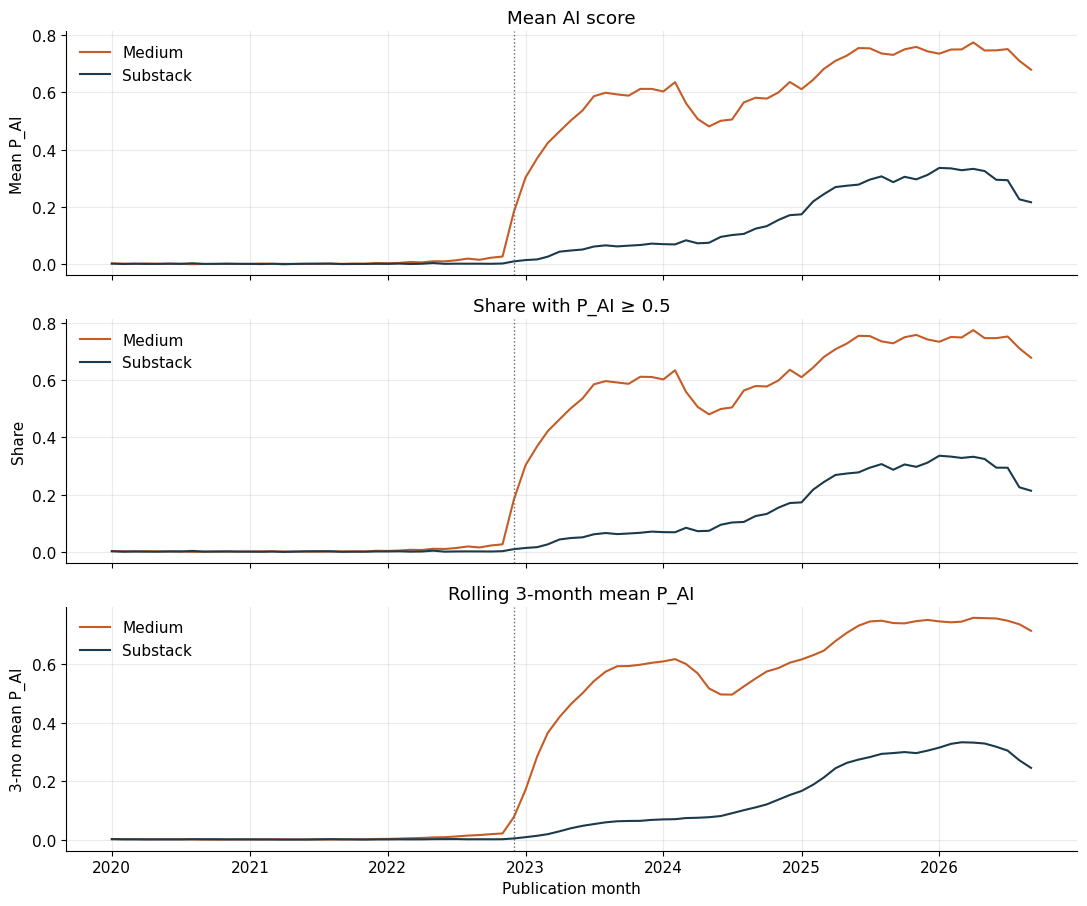

,platform,posts,mean_p_ai,share_05,share_08,share_95,median_words
year,,,,,,,
2020,medium,50000,0.0021,0.0015,0.0013,0.0011,734.0
2021,medium,50000,0.0023,0.0016,0.0014,0.0011,674.0
2022,medium,50000,0.0300,0.0295,0.0275,0.0254,649.0
2023,medium,50000,0.5188,0.5186,0.5109,0.4997,583.0
2024,medium,50000,0.5677,0.5675,0.5580,0.5454,600.0
2025,medium,50000,0.7209,0.7214,0.7107,0.6958,619.0
2026,medium,50000,0.7387,0.7403,0.7243,0.7022,769.0
2020,substack,50000,0.0023,0.0016,0.0015,0.0013,788.0
2021,substack,50000,0.0019,0.0013,0.0010,0.0008,813.0


In [4]:
def monthly(df):
    g = df.groupby("year_month").agg(
        posts=("post_id", "size"),
        mean_p_ai=("P_AI", "mean"),
        median_p_ai=("P_AI", "median"),
        p10=("P_AI", lambda x: x.quantile(0.1)),
        p90=("P_AI", lambda x: x.quantile(0.9)),
        share_05=("ai_05", "mean"),
        share_08=("ai_08", "mean"),
        share_95=("ai_95", "mean"),
        median_words=("word_count_source", "median"),
        mean_words=("word_count_source", "mean"),
    ).reset_index()
    # A month-start coordinate is used only to draw the time axis.
    g["dt"] = pd.to_datetime(g["year_month"], format="%Y-%m", errors="raise")
    g["roll3"] = g["mean_p_ai"].rolling(3, min_periods=1).mean()
    g["mom"] = g["mean_p_ai"].diff()
    return g

mm = monthly(m)
sm = monthly(s)
cut_naive = pd.to_datetime(CUT, format="%Y-%m")

fig, axes = plt.subplots(3, 1, figsize=(11, 9.2), sharex=True)
for ax, col, ylab, title in [
    (axes[0], "mean_p_ai", "Mean P_AI", "Mean AI score"),
    (axes[1], "share_05", "Share", "Share with P_AI ≥ 0.5"),
    (axes[2], "roll3", "3-mo mean P_AI", "Rolling 3-month mean P_AI"),
]:
    ax.plot(mm["dt"], mm[col], color="#c45c26", lw=1.5, label="Medium")
    ax.plot(sm["dt"], sm[col], color="#1b3a4b", lw=1.5, label="Substack")
    ax.axvline(cut_naive, color="#666666", ls=":", lw=1)
    ax.set_ylabel(ylab)
    ax.set_title(title)
    ax.legend(frameon=False)
axes[2].set_xlabel("Publication month")
fig.tight_layout()
plt.show()

# year summary
def year_sum(df, label):
    g = df.groupby("year").agg(
        posts=("post_id", "size"),
        mean_p_ai=("P_AI", "mean"),
        share_05=("ai_05", "mean"),
        share_08=("ai_08", "mean"),
        share_95=("ai_95", "mean"),
        median_words=("word_count_source", "median"),
    )
    g.insert(0, "platform", label)
    return g

display(pd.concat([year_sum(m, "medium"), year_sum(s, "substack")]).round(4))


## Spread within each month

Mean alone hides whether the month is a mix of near-0 and near-1 scores. Here are the 10th and 90th percentiles of `P_AI` by month.


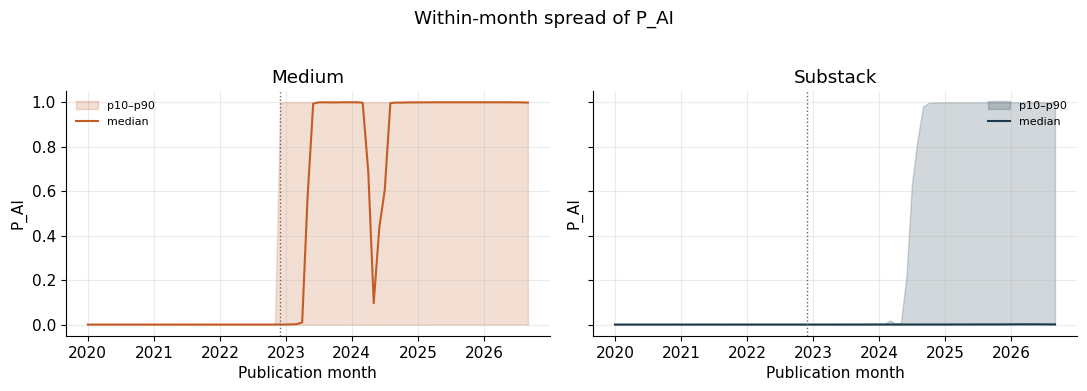

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
for ax, month_df, title, color in [
    (axes[0], mm, "Medium", "#c45c26"),
    (axes[1], sm, "Substack", "#1b3a4b"),
]:
    ax.fill_between(month_df["dt"], month_df["p10"], month_df["p90"], color=color, alpha=0.2, label="p10–p90")
    ax.plot(month_df["dt"], month_df["median_p_ai"], color=color, lw=1.5, label="median")
    ax.axvline(cut_naive, color="#666666", ls=":", lw=1)
    ax.set_title(title)
    ax.set_ylabel("P_AI")
    ax.legend(frameon=False, fontsize=8)
axes[0].set_xlabel("Publication month")
axes[1].set_xlabel("Publication month")
fig.suptitle("Within-month spread of P_AI", y=1.02)
fig.tight_layout()
plt.show()


## Before / after December 2022, and a slope break

First the plain averages. Then a line that allows a different slope before and after the cut.


,platform,period,posts,mean P_AI,share ≥0.5,share ≥0.8,median words
0,medium,post,204868,0.6257,0.6261,0.6154,632.0
1,medium,pre,145132,0.0057,0.0051,0.0044,688.0
2,substack,post,204934,0.1800,0.1795,0.1704,851.0
3,substack,pre,145066,0.0022,0.0016,0.0014,806.0


,platform,outcome,pre slope / mo,post slope / mo,slope change,change / SE,Dec 2022 jump,jump / SE
0,Medium,mean_p_ai,0.00049,0.00861,0.00812,7.61,0.4105,17.24
1,Medium,share_05,0.00048,0.00866,0.00817,7.67,0.4105,17.25
2,Substack,mean_p_ai,0.00001,0.00822,0.00820,14.42,-0.0143,-1.13
3,Substack,share_05,0.00001,0.00824,0.00822,14.41,-0.0145,-1.14


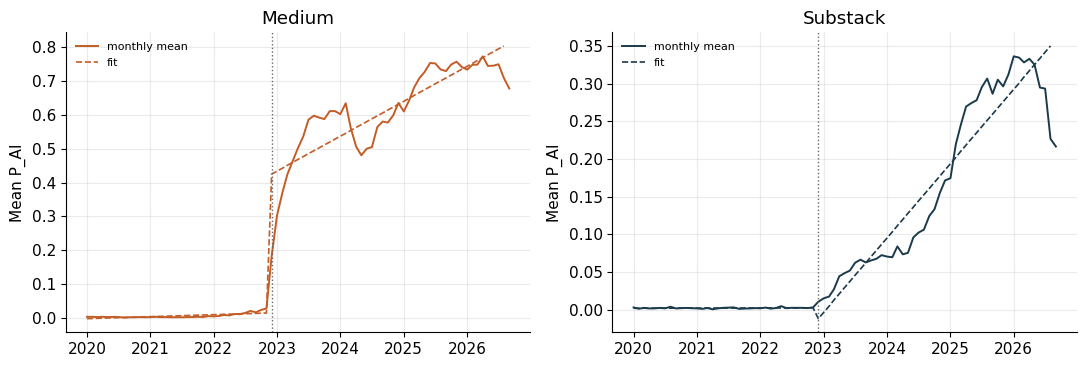

In [6]:
def prepost(df, label):
    rows = []
    for period, g in df.groupby("period"):
        rows.append({
            "platform": label,
            "period": period,
            "posts": len(g),
            "mean P_AI": g["P_AI"].mean(),
            "share ≥0.5": g["ai_05"].mean(),
            "share ≥0.8": g["ai_08"].mean(),
            "median words": g["word_count_source"].median(),
        })
    return pd.DataFrame(rows)

display(pd.concat([prepost(m, "medium"), prepost(s, "substack")], ignore_index=True).round(4))

def broken(month_df, ycol):
    d = month_df[month_df["dt"] < "2026-09-01"].copy()
    d["t"] = (d["dt"].dt.year - 2020) * 12 + (d["dt"].dt.month - 1)
    cut = 35
    X = np.column_stack([
        np.ones(len(d)),
        d["t"],
        (d["t"] >= cut).astype(float),
        np.maximum(d["t"] - cut, 0.0),
    ])
    y = d[ycol].to_numpy(float)
    beta, *_ = np.linalg.lstsq(X, y, rcond=None)
    resid = y - X @ beta
    dof = max(len(y) - 4, 1)
    se = np.sqrt(np.diag((resid @ resid / dof) * np.linalg.inv(X.T @ X)))
    d["fitted"] = X @ beta
    return d, beta, se

rows = []
fits = {}
for label, month_df in [("Medium", mm), ("Substack", sm)]:
    for ycol in ["mean_p_ai", "share_05"]:
        fit, beta, se = broken(month_df, ycol)
        fits[(label, ycol)] = fit
        rows.append({
            "platform": label,
            "outcome": ycol,
            "pre slope / mo": round(beta[1], 5),
            "post slope / mo": round(beta[1] + beta[3], 5),
            "slope change": round(beta[3], 5),
            "change / SE": round(beta[3] / se[3], 2),
            "Dec 2022 jump": round(beta[2], 4),
            "jump / SE": round(beta[2] / se[2], 2),
        })
display(pd.DataFrame(rows))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for ax, plat, color in [(axes[0], "Medium", "#c45c26"), (axes[1], "Substack", "#1b3a4b")]:
    raw = mm if plat == "Medium" else sm
    fit = fits[(plat, "mean_p_ai")]
    ax.plot(raw["dt"], raw["mean_p_ai"], color=color, lw=1.4, label="monthly mean")
    ax.plot(fit["dt"], fit["fitted"], color=color, ls="--", lw=1.2, label="fit")
    ax.axvline(cut_naive, color="#666666", ls=":", lw=1)
    ax.set_title(plat)
    ax.set_ylabel("Mean P_AI")
    ax.legend(frameon=False, fontsize=8)
fig.tight_layout()
plt.show()


## Months around the cut

Same idea as an event study: month 0 is December 2022. Looking at a short window so the pre and post sides are easier to compare by eye.


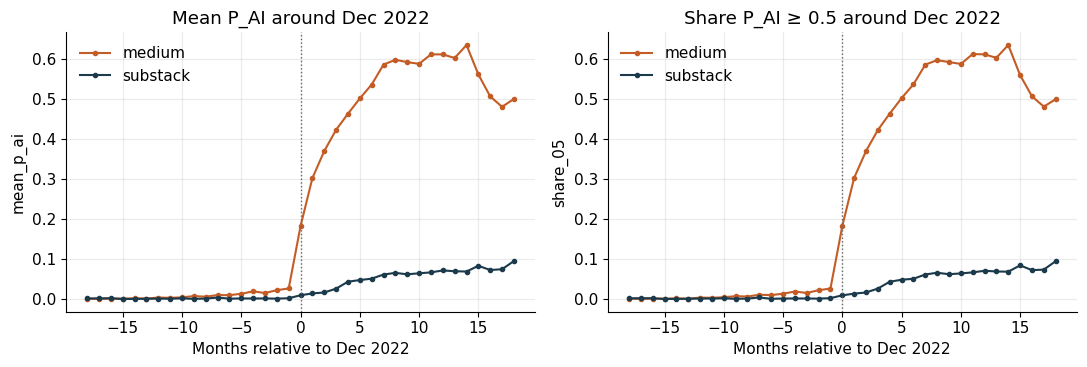

mean P_AI, last 12 pre months vs first 12 post months
  medium: pre=0.0127  post=0.4795  delta=0.4667
  substack: pre=0.0025  post=0.0449  delta=0.0424


In [7]:
def event(month_df, label, window=18):
    d = month_df.copy()
    d["k"] = ((d["dt"].dt.year - 2022) * 12 + (d["dt"].dt.month - 12))
    d = d[(d["k"] >= -window) & (d["k"] <= window)].copy()
    d["platform"] = label
    return d

ev = pd.concat([event(mm, "medium"), event(sm, "substack")], ignore_index=True)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharex=True)
for ax, col, title in [
    (axes[0], "mean_p_ai", "Mean P_AI around Dec 2022"),
    (axes[1], "share_05", "Share P_AI ≥ 0.5 around Dec 2022"),
]:
    for plat, color in [("medium", "#c45c26"), ("substack", "#1b3a4b")]:
        g = ev.loc[ev.platform == plat]
        ax.plot(g["k"], g[col], color=color, lw=1.5, marker="o", ms=3, label=plat)
    ax.axvline(0, color="#666666", ls=":", lw=1)
    ax.set_xlabel("Months relative to Dec 2022")
    ax.set_ylabel(col)
    ax.set_title(title)
    ax.legend(frameon=False)
fig.tight_layout()
plt.show()

# first 12 post months vs last 12 pre months
def window_mean(month_df, ks, col="mean_p_ai"):
    d = month_df.copy()
    d["k"] = ((d["dt"].dt.year - 2022) * 12 + (d["dt"].dt.month - 12))
    return d.loc[d["k"].isin(ks), col].mean()

print("mean P_AI, last 12 pre months vs first 12 post months")
for label, month_df in [("medium", mm), ("substack", sm)]:
    pre = window_mean(month_df, list(range(-12, 0)))
    post = window_mean(month_df, list(range(0, 12)))
    print(f"  {label}: pre={pre:.4f}  post={post:.4f}  delta={post-pre:.4f}")


## Which family, when the post looks AI

Restrict to `P_AI ≥ 0.5`, then look at the `*_GIVEN_AI` mix over time.


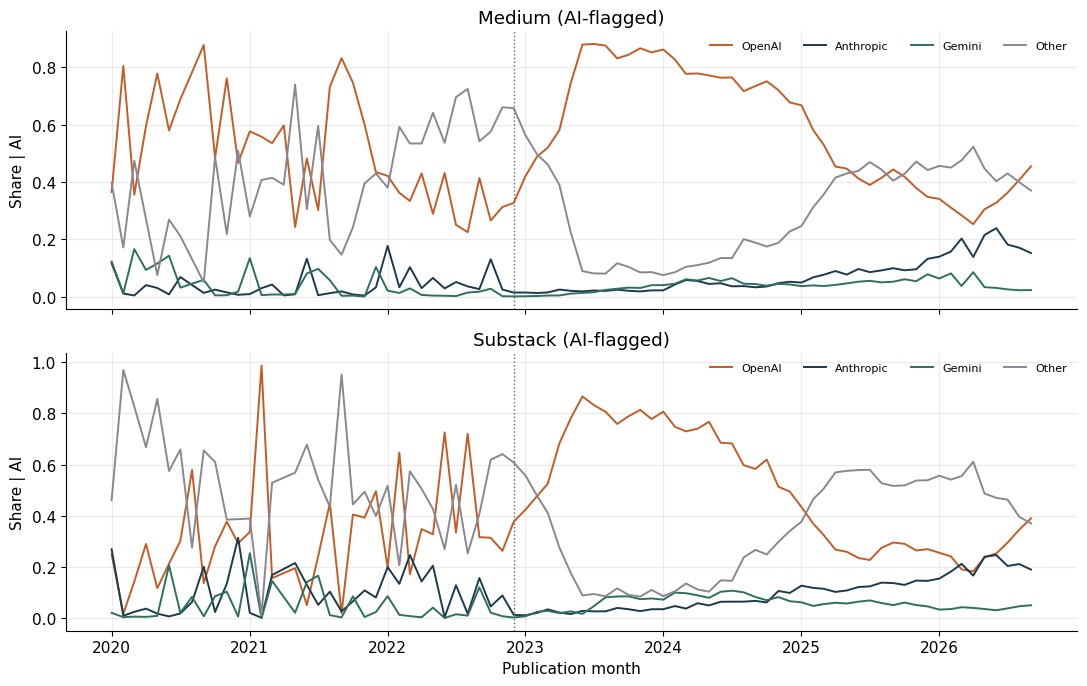

,platform,OpenAI,Anthropic,Gemini,Other,n_ai
year,,,,,,
2020,medium,0.617,0.034,0.077,0.271,76
2021,medium,0.560,0.027,0.048,0.365,81
2022,medium,0.323,0.032,0.006,0.639,1473
2023,medium,0.767,0.020,0.020,0.193,25931
2024,medium,0.767,0.042,0.049,0.142,28376
2025,medium,0.442,0.090,0.052,0.415,36068
2026,medium,0.333,0.179,0.045,0.442,37013
2020,substack,0.311,0.099,0.060,0.530,81
2021,substack,0.308,0.100,0.087,0.505,66


Medium PREDICTION among AI-flagged posts, by year


PREDICTION,Anthropic,Gemini,OpenAI,Other
year,,,,
2020,0.026,0.066,0.645,0.263
2021,0.000,0.049,0.568,0.383
2022,0.024,0.004,0.305,0.666
2023,0.014,0.018,0.784,0.184
2024,0.033,0.046,0.797,0.124
2025,0.080,0.049,0.448,0.422
2026,0.174,0.043,0.338,0.446


Substack PREDICTION among AI-flagged posts, by year


PREDICTION,Anthropic,Gemini,OpenAI,Other
year,,,,
2020,0.086,0.062,0.296,0.556
2021,0.061,0.091,0.303,0.545
2022,0.074,0.022,0.375,0.529
2023,0.021,0.050,0.802,0.127
2024,0.062,0.081,0.656,0.202
2025,0.115,0.054,0.278,0.553
2026,0.193,0.035,0.246,0.527


In [8]:
def family_month(df, label):
    d = df.loc[df["ai_05"]].copy()
    g = d.groupby("year_month")[GIVEN_COLS].mean()
    g["n"] = d.groupby("year_month").size()
    g = g.reset_index()
    g["dt"] = pd.to_datetime(g["year_month"], format="%Y-%m", errors="raise")
    g["platform"] = label
    return g

mf = family_month(m, "medium")
sf = family_month(s, "substack")

fig, axes = plt.subplots(2, 1, figsize=(11, 7), sharex=True)
for ax, fam, title in [(axes[0], mf, "Medium (AI-flagged)"), (axes[1], sf, "Substack (AI-flagged)")]:
    for col, name in GIVEN.items():
        ax.plot(fam["dt"], fam[col], color=FAM_COLORS[name], lw=1.4, label=name)
    ax.axvline(cut_naive, color="#666666", ls=":", lw=1)
    ax.set_ylabel("Share | AI")
    ax.set_title(title)
    ax.legend(frameon=False, ncol=4, fontsize=8)
axes[1].set_xlabel("Publication month")
fig.tight_layout()
plt.show()

# stacked by year among AI-flagged
def family_year(df, label):
    d = df.loc[df["ai_05"]].copy()
    g = d.groupby("year")[GIVEN_COLS].mean()
    g.columns = [GIVEN[c] for c in g.columns]
    g["n_ai"] = d.groupby("year").size()
    g.insert(0, "platform", label)
    return g

display(pd.concat([family_year(m, "medium"), family_year(s, "substack")]).round(3))

# PREDICTION among AI-flagged by year (counts)
print("Medium PREDICTION among AI-flagged posts, by year")
display(pd.crosstab(m.loc[m.ai_05, "year"], m.loc[m.ai_05, "PREDICTION"], normalize="index").round(3))
print("Substack PREDICTION among AI-flagged posts, by year")
display(pd.crosstab(s.loc[s.ai_05, "year"], s.loc[s.ai_05, "PREDICTION"], normalize="index").round(3))


## Topics

Codes only — 0–8 on Medium, 0–9 on Substack. No names in the CSV. Still useful to see which buckets carry the AI rise.


,platform,posts,mean_p_ai,share_05,median_words,share_of_sample
topic_code,,,,,,
0,medium,12765,0.2956,0.2953,449.0,0.0365
1,medium,13183,0.3218,0.3216,730.0,0.0377
2,medium,35579,0.4145,0.4145,712.0,0.1017
3,medium,18571,0.4058,0.4063,654.0,0.0531
4,medium,5582,0.3556,0.3551,700.0,0.0159
5,medium,13560,0.2805,0.2802,568.0,0.0387
6,medium,12683,0.2822,0.2820,796.0,0.0362
7,medium,200031,0.3642,0.3641,622.0,0.5715
8,medium,38046,0.4340,0.4342,803.0,0.1087


period,platform,post,pre,delta
topic_code,,,,
0,medium,0.5085,0.0048,0.5038
1,medium,0.5705,0.0047,0.5657
2,medium,0.7274,0.0079,0.7195
3,medium,0.6148,0.0065,0.6083
4,medium,0.6404,0.0053,0.6351
5,medium,0.4280,0.0050,0.4230
6,medium,0.5351,0.0030,0.5322
7,medium,0.6268,0.0059,0.6209
8,medium,0.6906,0.0042,0.6864


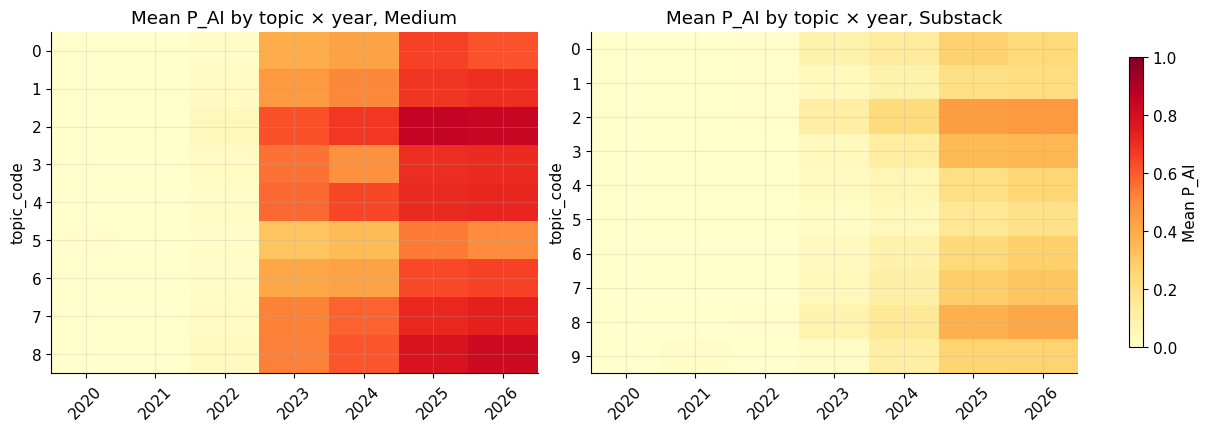

Where AI-flagged posts sit across topics (row = year)


topic_code,platform,0,1,2,3,4,5,6,7,8,9
year,,,,,,,,,,,
2020,medium,0.026,0.013,0.105,0.092,0.000,0.105,0.000,0.632,0.026,NaN
2021,medium,0.062,0.037,0.099,0.037,0.000,0.037,0.037,0.543,0.148,NaN
2022,medium,0.026,0.031,0.176,0.039,0.011,0.014,0.018,0.576,0.110,NaN
2023,medium,0.026,0.034,0.138,0.054,0.020,0.021,0.022,0.577,0.107,NaN
2024,medium,0.029,0.033,0.110,0.049,0.020,0.027,0.024,0.598,0.110,NaN
2025,medium,0.035,0.034,0.109,0.059,0.012,0.038,0.032,0.564,0.118,NaN
2026,medium,0.026,0.031,0.104,0.069,0.013,0.030,0.031,0.529,0.167,NaN
2020,substack,0.012,0.148,0.099,0.037,0.000,0.025,0.012,0.617,0.049,0.000
2021,substack,0.030,0.061,0.197,0.061,0.045,0.000,0.030,0.500,0.061,0.015


In [9]:
def topic_table(df, label):
    g = df.groupby("topic_code").agg(
        posts=("post_id", "size"),
        mean_p_ai=("P_AI", "mean"),
        share_05=("ai_05", "mean"),
        median_words=("word_count_source", "median"),
    )
    g["share_of_sample"] = g["posts"] / g["posts"].sum()
    g.insert(0, "platform", label)
    return g

display(pd.concat([topic_table(m, "medium"), topic_table(s, "substack")]).round(4))

# pre/post by topic
def topic_period(df, label):
    g = df.groupby(["topic_code", "period"]).agg(
        posts=("post_id", "size"),
        mean_p_ai=("P_AI", "mean"),
        share_05=("ai_05", "mean"),
    ).reset_index()
    wide = g.pivot(index="topic_code", columns="period", values="mean_p_ai")
    wide["delta"] = wide.get("post") - wide.get("pre")
    wide.insert(0, "platform", label)
    return wide

display(pd.concat([topic_period(m, "medium"), topic_period(s, "substack")]).round(4))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), layout="constrained")
for ax, df, title in [(axes[0], m, "Medium"), (axes[1], s, "Substack")]:
    heat = df.pivot_table(index="topic_code", columns="year", values="P_AI", aggfunc="mean")
    im = ax.imshow(heat.to_numpy(), aspect="auto", cmap="YlOrRd", vmin=0, vmax=1)
    ax.set_yticks(range(len(heat.index)))
    ax.set_yticklabels(heat.index)
    ax.set_xticks(range(len(heat.columns)))
    ax.set_xticklabels([int(c) for c in heat.columns], rotation=45)
    ax.set_title(f"Mean P_AI by topic × year, {title}")
    ax.set_ylabel("topic_code")
fig.colorbar(im, ax=axes.ravel().tolist(), shrink=0.85, label="Mean P_AI")
plt.show()

# topic share of AI-flagged posts over years (composition)
def ai_topic_share(df, label):
    d = df.loc[df["ai_05"]].copy()
    if d.empty:
        return pd.DataFrame()
    ct = pd.crosstab(d["year"], d["topic_code"], normalize="index")
    ct.insert(0, "platform", label)
    return ct

print("Where AI-flagged posts sit across topics (row = year)")
display(pd.concat([ai_topic_share(m, "medium"), ai_topic_share(s, "substack")]).round(3))


## Length

Overall, by AI flag, by topic, and over time. Substack posts run longer. Worth checking whether AI-flagged posts are systematically shorter or longer.


,platform,group,n,median,mean,p10,p90
0,medium,all,350000,654.0,883.5,274.0,1662.0
1,medium,P_AI < 0.5,220982,675.0,908.5,262.0,1724.0
2,medium,P_AI ≥ 0.5,129018,627.0,840.8,296.0,1555.0
3,substack,all,350000,832.0,1124.6,273.0,2169.0
4,substack,P_AI < 0.5,312975,835.0,1124.3,270.0,2176.0
5,substack,P_AI ≥ 0.5,37025,817.0,1127.2,312.0,2093.0


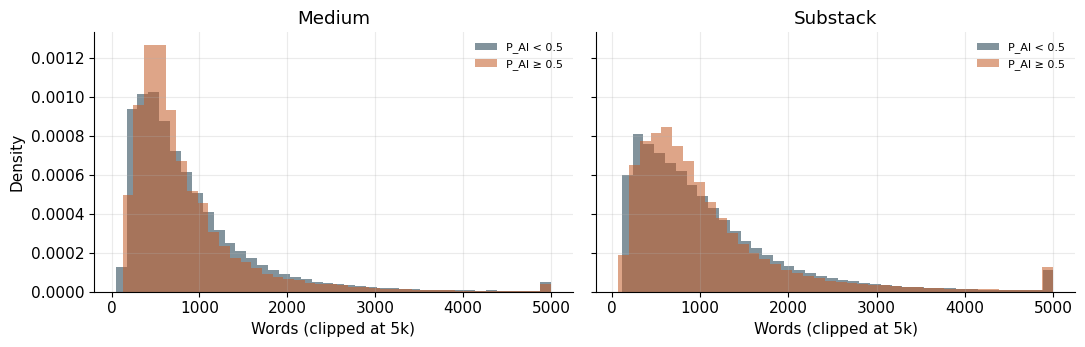

,platform,posts,mean_p_ai,share_05,median_words
len_q,,,,,
Q1 short,medium,87550,0.3476,0.3476,300.0
Q2,medium,87543,0.4302,0.4304,530.0
Q3,medium,87520,0.3759,0.3757,823.0
Q4 long,medium,87387,0.3207,0.3207,1510.0
Q1 short,substack,87716,0.0940,0.0936,306.0
Q2,substack,87356,0.1236,0.1230,641.0
Q3,substack,87486,0.1126,0.1120,1063.0
Q4 long,substack,87442,0.0952,0.0946,1960.0


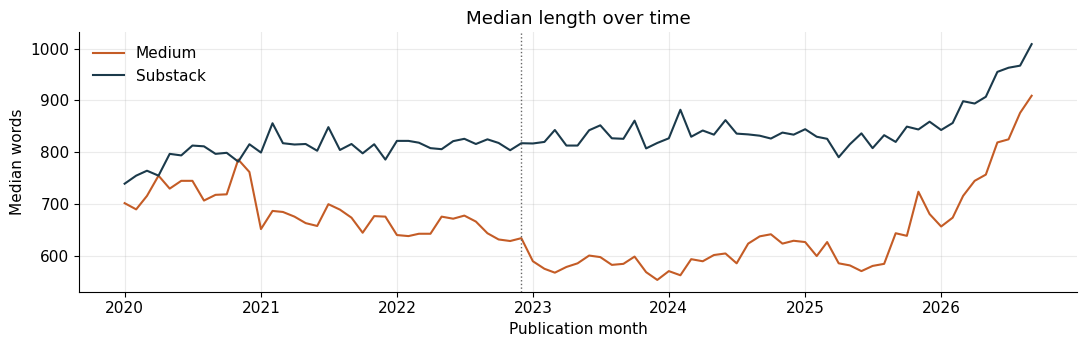

median words by topic


,medium,substack
topic_code,,
0,449.0,745.0
1,730.0,770.0
2,712.0,859.0
3,654.0,819.0
4,700.0,828.0
5,568.0,795.0
6,796.0,912.0
7,622.0,821.0
8,803.0,888.0


In [10]:
def length_bits(df, label):
    rows = []
    for name, mask in [("all", slice(None)), ("P_AI < 0.5", ~df["ai_05"]), ("P_AI ≥ 0.5", df["ai_05"])]:
        g = df.loc[mask, "word_count_source"] if not isinstance(mask, slice) else df["word_count_source"]
        rows.append({
            "platform": label, "group": name, "n": int(len(g)),
            "median": g.median(), "mean": g.mean(),
            "p10": g.quantile(0.1), "p90": g.quantile(0.9),
        })
    return pd.DataFrame(rows)

display(pd.concat([length_bits(m, "medium"), length_bits(s, "substack")], ignore_index=True).round(1))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True)
for ax, df, title in [(axes[0], m, "Medium"), (axes[1], s, "Substack")]:
    for flag, color, lab in [(False, "#1b3a4b", "P_AI < 0.5"), (True, "#c45c26", "P_AI ≥ 0.5")]:
        ax.hist(df.loc[df.ai_05 == flag, "word_count_source"].clip(upper=5000),
                bins=40, density=True, alpha=0.55, color=color, label=lab)
    ax.set_title(title)
    ax.set_xlabel("Words (clipped at 5k)")
    ax.legend(frameon=False, fontsize=8)
axes[0].set_ylabel("Density")
fig.tight_layout()
plt.show()

# AI rate by word-count quartile
def ai_by_length_q(df, label):
    d = df.copy()
    d["len_q"] = pd.qcut(d["word_count_source"], 4, labels=["Q1 short", "Q2", "Q3", "Q4 long"])
    g = d.groupby("len_q", observed=True).agg(
        posts=("post_id", "size"),
        mean_p_ai=("P_AI", "mean"),
        share_05=("ai_05", "mean"),
        median_words=("word_count_source", "median"),
    )
    g.insert(0, "platform", label)
    return g

display(pd.concat([ai_by_length_q(m, "medium"), ai_by_length_q(s, "substack")]).round(4))

fig, ax = plt.subplots(figsize=(11, 3.6))
ax.plot(mm["dt"], mm["median_words"], color="#c45c26", label="Medium")
ax.plot(sm["dt"], sm["median_words"], color="#1b3a4b", label="Substack")
ax.axvline(cut_naive, color="#666666", ls=":", lw=1)
ax.set_ylabel("Median words")
ax.set_xlabel("Publication month")
ax.set_title("Median length over time")
ax.legend(frameon=False)
fig.tight_layout()
plt.show()

print("median words by topic")
display(pd.concat({
    "medium": m.groupby("topic_code")["word_count_source"].median(),
    "substack": s.groupby("topic_code")["word_count_source"].median(),
}, axis=1).round(0))


## Medium vs Substack gap

Same sampling idea, different AI levels after 2022. The difference grows for a few years.


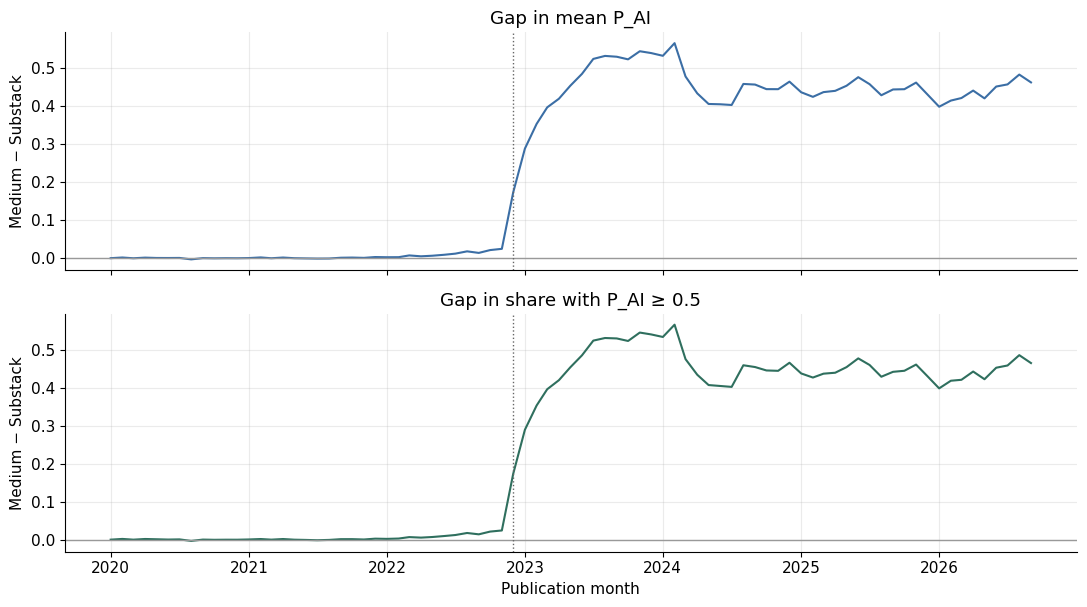

,month,platform,posts,mean P_AI,share ≥0.5,median words
0,2020-01,medium,2869,0.0028,0.0024,702.0
1,2020-01,substack,2644,0.0030,0.0026,739.5
2,2022-11,medium,4284,0.0275,0.0266,629.0
3,2022-11,substack,4898,0.0032,0.0027,804.0
4,2022-12,medium,4868,0.1830,0.1826,634.5
5,2022-12,substack,4934,0.0105,0.0097,817.5
6,2023-06,medium,3797,0.5360,0.5359,601.0
7,2023-06,substack,4018,0.0519,0.0510,842.5
8,2024-06,medium,3610,0.5001,0.4992,605.0
9,2024-06,substack,4004,0.0959,0.0949,862.0


mean gap after Dec 2022: 0.4458
max gap month: 2024-02 0.5648


In [11]:
gap = mm.merge(sm, on="dt", suffixes=("_m", "_s"))
gap["p_ai_gap"] = gap["mean_p_ai_m"] - gap["mean_p_ai_s"]
gap["share_gap"] = gap["share_05_m"] - gap["share_05_s"]

fig, axes = plt.subplots(2, 1, figsize=(11, 6.2), sharex=True)
axes[0].plot(gap["dt"], gap["p_ai_gap"], color="#3b6ea5", lw=1.5)
axes[0].axhline(0, color="#999999", lw=1)
axes[0].axvline(cut_naive, color="#666666", ls=":", lw=1)
axes[0].set_ylabel("Medium − Substack")
axes[0].set_title("Gap in mean P_AI")

axes[1].plot(gap["dt"], gap["share_gap"], color="#2f6f5e", lw=1.5)
axes[1].axhline(0, color="#999999", lw=1)
axes[1].axvline(cut_naive, color="#666666", ls=":", lw=1)
axes[1].set_ylabel("Medium − Substack")
axes[1].set_xlabel("Publication month")
axes[1].set_title("Gap in share with P_AI ≥ 0.5")
fig.tight_layout()
plt.show()

snaps = ["2020-01", "2022-11", "2022-12", "2023-06", "2024-06", "2025-06", "2026-08"]
rows = []
for ym in snaps:
    for label, month_df in [("medium", mm), ("substack", sm)]:
        r = month_df.loc[month_df["year_month"] == ym]
        if r.empty:
            continue
        r = r.iloc[0]
        rows.append({
            "month": ym, "platform": label, "posts": int(r["posts"]),
            "mean P_AI": r["mean_p_ai"], "share ≥0.5": r["share_05"],
            "median words": r["median_words"],
        })
display(pd.DataFrame(rows).round(4))

print("mean gap after Dec 2022:", round(gap.loc[gap.dt >= cut_naive, "p_ai_gap"].mean(), 4))
print("max gap month:", gap.loc[gap["p_ai_gap"].idxmax(), "year_month_m"],
      round(gap["p_ai_gap"].max(), 4))


## Where the score mass sits

Most posts are near 0 or near 1. The middle barely exists. That is why a 0.5 cut and a 0.8 cut often move together.


,medium,substack
P_AI,,
0–0.05,0.6173,0.8816
0.05–0.2,0.0075,0.0071
0.2–0.5,0.0065,0.0055
0.5–0.8,0.0066,0.0054
0.8–0.95,0.0091,0.0069
0.95–1,0.3529,0.0935


period               post     pre
platform bin                     
medium   0.05–0.2  0.0119  0.0013
         0.2–0.5   0.0106  0.0008
         0.5–0.8   0.0108  0.0007
         0.8–0.95  0.0150  0.0006
         0.95–1    0.6003  0.0037
         0–0.05    0.3514  0.9928
substack 0.05–0.2  0.0117  0.0007
         0.2–0.5   0.0092  0.0003
         0.5–0.8   0.0091  0.0002
         0.8–0.95  0.0115  0.0002
         0.95–1    0.1589  0.0011
         0–0.05    0.7996  0.9974

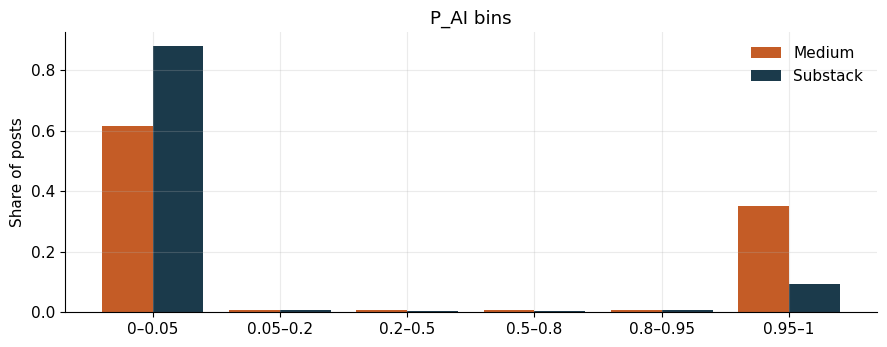

In [12]:
bins = [0, 0.05, 0.2, 0.5, 0.8, 0.95, 1.0001]
labs = ["0–0.05", "0.05–0.2", "0.2–0.5", "0.5–0.8", "0.8–0.95", "0.95–1"]

def mass(df, label):
    cat = pd.cut(df["P_AI"], bins=bins, labels=labs, right=False, include_lowest=True)
    return cat.value_counts(normalize=True).reindex(labs).rename(label)

mass_tbl = pd.concat([mass(m, "medium"), mass(s, "substack")], axis=1)
display(mass_tbl.round(4))

# mass by period
def mass_period(df, label):
    rows = []
    for period, g in df.groupby("period"):
        cat = pd.cut(g["P_AI"], bins=bins, labels=labs, right=False, include_lowest=True)
        share = cat.value_counts(normalize=True).reindex(labs)
        for lab, v in share.items():
            rows.append({"platform": label, "period": period, "bin": lab, "share": v})
    return pd.DataFrame(rows)

mp = pd.concat([mass_period(m, "medium"), mass_period(s, "substack")], ignore_index=True)
display(mp.pivot_table(index=["platform", "bin"], columns="period", values="share").round(4))

fig, ax = plt.subplots(figsize=(9, 3.6))
x = np.arange(len(labs))
ax.bar(x - 0.2, mass_tbl["medium"], 0.4, color="#c45c26", label="Medium")
ax.bar(x + 0.2, mass_tbl["substack"], 0.4, color="#1b3a4b", label="Substack")
ax.set_xticks(x)
ax.set_xticklabels(labs)
ax.set_ylabel("Share of posts")
ax.set_title("P_AI bins")
ax.legend(frameon=False)
fig.tight_layout()
plt.show()


## Thresholds 0.5 / 0.8 / 0.95

Same story at stricter cuts. Levels drop, the post-2022 rise stays.


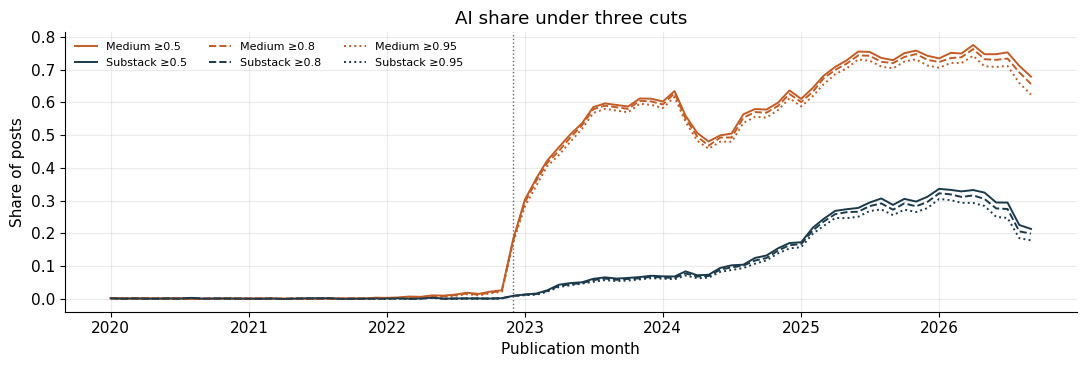

,medium ≥0.5,medium ≥0.8,medium ≥0.95,substack ≥0.5,substack ≥0.8,substack ≥0.95
year,,,,,,
2020,0.0015,0.0013,0.0011,0.0016,0.0015,0.0013
2021,0.0016,0.0014,0.0011,0.0013,0.0010,0.0008
2022,0.0295,0.0275,0.0254,0.0027,0.0024,0.0021
2023,0.5186,0.5109,0.4997,0.0509,0.0479,0.0445
2024,0.5675,0.5580,0.5454,0.1075,0.1020,0.0950
2025,0.7214,0.7107,0.6958,0.2750,0.2634,0.2478
2026,0.7403,0.7243,0.7022,0.3014,0.2844,0.2630


In [13]:
fig, ax = plt.subplots(figsize=(11, 3.8))
for thr, col, ls in [(0.5, "share_05", "-"), (0.8, "share_08", "--"), (0.95, "share_95", ":")]:
    ax.plot(mm["dt"], mm[col], color="#c45c26", ls=ls, lw=1.4, label=f"Medium ≥{thr}")
    ax.plot(sm["dt"], sm[col], color="#1b3a4b", ls=ls, lw=1.4, label=f"Substack ≥{thr}")
ax.axvline(cut_naive, color="#666666", ls=":", lw=1)
ax.set_ylabel("Share of posts")
ax.set_xlabel("Publication month")
ax.set_title("AI share under three cuts")
ax.legend(frameon=False, ncol=3, fontsize=8)
fig.tight_layout()
plt.show()

thr_year = pd.concat([
    m.groupby("year").agg(**{f"medium ≥{t}": (c, "mean") for t, c in [(0.5,"ai_05"),(0.8,"ai_08"),(0.95,"ai_95")]}),
    s.groupby("year").agg(**{f"substack ≥{t}": (c, "mean") for t, c in [(0.5,"ai_05"),(0.8,"ai_08"),(0.95,"ai_95")]}),
], axis=1)
display(thr_year.round(4))


## Creators and publication dates

Most posts have one creator. Substack has a small coauthor tail. Medium's 7,341 rows with `creator_count = 0` all have valid publication dates and are included in the time plots. A zero creator count does not imply a missing date.


In [14]:
print("Medium creator_count")
display(medium["creator_count"].value_counts().sort_index().to_frame("posts"))
print("Substack creator_count (top)")
display(substack["creator_count"].value_counts().sort_index().head(8).to_frame("posts"))

print(f"missing publication dates: medium={medium.published_date.isna().sum():,}, "
      f"substack={substack.published_date.isna().sum():,}")
print("Medium creator_count=0 rows with valid publication dates:",
      f"{((medium.creator_count == 0) & medium.published_date.notna()).sum():,}")


Medium creator_count


,posts
creator_count,
0,7341
1,342659


Substack creator_count (top)


,posts
creator_count,
0,9551
1,334125
2,5172
3,824
4,209
5,68
6,19
7,10


missing publication dates: medium=0, substack=0
Medium creator_count=0 rows with valid publication dates: 7,341


## Detector tokens

How much text the scorer saw, and whether that lines up with `P_AI`.


,platform,median tokens,mean tokens,"corr(tokens, words)","corr(tokens, P_AI)",median PREDICTION_SCORE,median PREDICTION_SCORE | AI
0,medium,768,649.3,0.410,0.040,0.527,0.956
1,substack,768,673.8,0.373,0.031,0.458,0.927


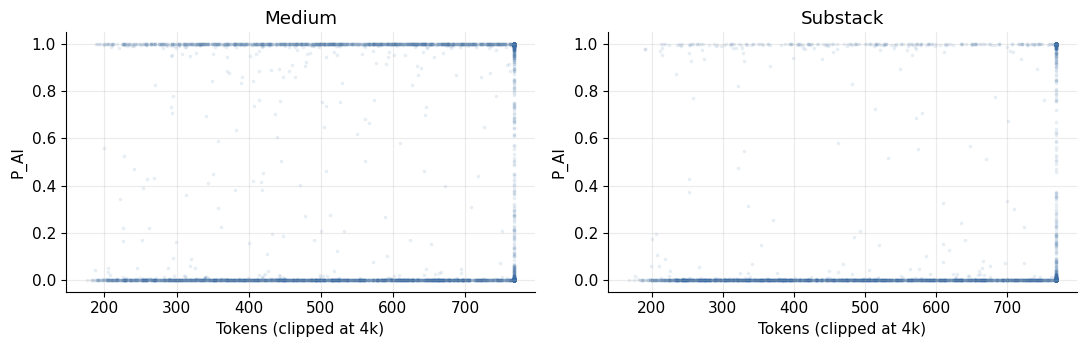

In [15]:
def token_bits(df, label):
    return {
        "platform": label,
        "median tokens": int(df["DETECTOR_TOKENS_USED"].median()),
        "mean tokens": round(df["DETECTOR_TOKENS_USED"].mean(), 1),
        "corr(tokens, words)": round(df["DETECTOR_TOKENS_USED"].corr(df["word_count_source"]), 3),
        "corr(tokens, P_AI)": round(df["DETECTOR_TOKENS_USED"].corr(df["P_AI"]), 3),
        "median PREDICTION_SCORE": round(df["PREDICTION_SCORE"].median(), 3),
        "median PREDICTION_SCORE | AI": round(df.loc[df.ai_05, "PREDICTION_SCORE"].median(), 3),
    }

display(pd.DataFrame([token_bits(m, "medium"), token_bits(s, "substack")]))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
for ax, df, title in [(axes[0], m.sample(8000, random_state=0), "Medium"),
                      (axes[1], s.sample(8000, random_state=0), "Substack")]:
    ax.scatter(df["DETECTOR_TOKENS_USED"].clip(upper=4000), df["P_AI"],
               s=3, alpha=0.08, color="#3b6ea5")
    ax.set_title(title)
    ax.set_xlabel("Tokens (clipped at 4k)")
    ax.set_ylabel("P_AI")
fig.tight_layout()
plt.show()


## Month-of-year pattern

Quick check for seasonality in the AI score after 2023, when the levels are high enough to see a pattern.


,platform,mean_p_ai,share_05,posts
month,,,,
1,medium,0.5765,0.5767,18340
2,medium,0.6136,0.6145,17960
3,medium,0.6132,0.6127,17587
4,medium,0.6313,0.6317,17451
5,medium,0.6282,0.6292,17943
6,medium,0.6523,0.6529,17684
7,medium,0.6664,0.6676,18829
8,medium,0.6598,0.6604,18503
9,medium,0.6473,0.6469,16555


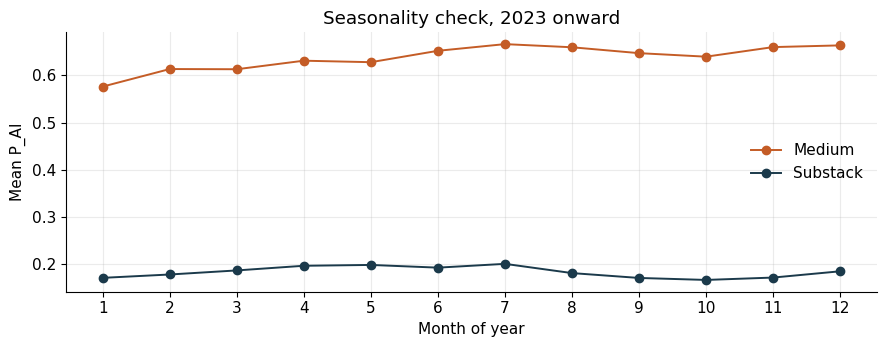

In [16]:
def moy(df, label):
    d = df.loc[df["year"] >= 2023].copy()
    g = d.groupby("month").agg(mean_p_ai=("P_AI", "mean"), share_05=("ai_05", "mean"), posts=("post_id", "size"))
    g.insert(0, "platform", label)
    return g

display(pd.concat([moy(m, "medium"), moy(s, "substack")]).round(4))

fig, ax = plt.subplots(figsize=(9, 3.6))
for df, color, lab in [(m, "#c45c26", "Medium"), (s, "#1b3a4b", "Substack")]:
    g = df.loc[df.year >= 2023].groupby("month")["P_AI"].mean()
    ax.plot(g.index, g.values, color=color, marker="o", lw=1.4, label=lab)
ax.set_xticks(range(1, 13))
ax.set_xlabel("Month of year")
ax.set_ylabel("Mean P_AI")
ax.set_title("Seasonality check, 2023 onward")
ax.legend(frameon=False)
fig.tight_layout()
plt.show()


## Month-to-month changes

Where did the score jump the most in a single month?


Biggest month-to-month rises in mean P_AI


,platform,year_month,mean_p_ai,mom,share_05
0,medium,2022-12,0.1830,0.1556,0.1826
1,medium,2023-01,0.3028,0.1198,0.3030
2,medium,2023-02,0.3701,0.0673,0.3697
3,medium,2024-08,0.5638,0.0592,0.5635
4,medium,2023-03,0.4231,0.0530,0.4223
5,medium,2023-07,0.5857,0.0497,0.5854
6,medium,2023-04,0.4631,0.0400,0.4631
7,medium,2023-05,0.5013,0.0381,0.5019
8,substack,2025-02,0.2194,0.0450,0.2178
9,substack,2025-03,0.2445,0.0251,0.2440


Biggest month-to-month drops


,platform,year_month,mean_p_ai,mom,share_05
0,medium,2024-03,0.5612,-0.0733,0.5593
1,medium,2024-04,0.5064,-0.0549,0.5064
2,medium,2026-08,0.7089,-0.0408,0.7112
3,medium,2026-09,0.6782,-0.0308,0.6784
4,medium,2026-05,0.7448,-0.0281,0.7467
5,medium,2024-05,0.4804,-0.0259,0.4806
6,medium,2025-01,0.6102,-0.0250,0.6104
7,medium,2025-08,0.7345,-0.0178,0.7354
8,substack,2026-08,0.2267,-0.0666,0.2258
9,substack,2026-06,0.2946,-0.0304,0.2944


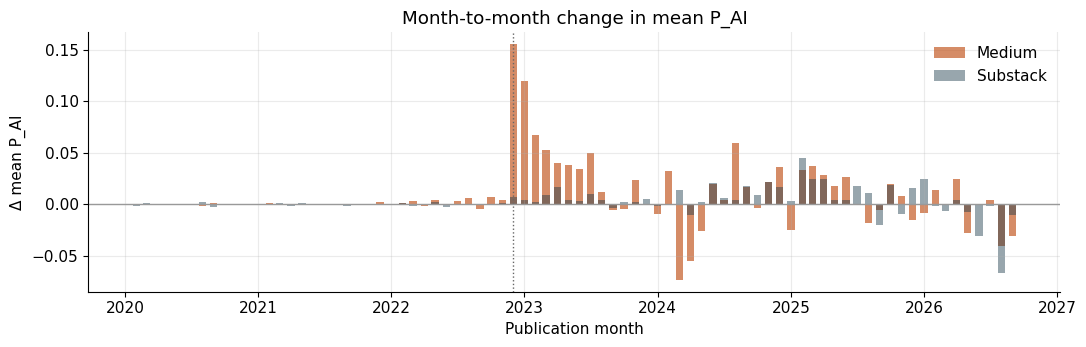

In [17]:
def top_moves(month_df, label, n=8):
    d = month_df.dropna(subset=["mom"]).copy()
    d["platform"] = label
    up = d.nlargest(n, "mom")[["platform", "year_month", "mean_p_ai", "mom", "share_05"]]
    down = d.nsmallest(n, "mom")[["platform", "year_month", "mean_p_ai", "mom", "share_05"]]
    return up, down

print("Biggest month-to-month rises in mean P_AI")
ups = pd.concat([top_moves(mm, "medium")[0], top_moves(sm, "substack")[0]], ignore_index=True)
display(ups.round(4))
print("Biggest month-to-month drops")
downs = pd.concat([top_moves(mm, "medium")[1], top_moves(sm, "substack")[1]], ignore_index=True)
display(downs.round(4))

fig, ax = plt.subplots(figsize=(11, 3.6))
ax.bar(mm["dt"], mm["mom"], width=20, color="#c45c26", alpha=0.7, label="Medium")
ax.bar(sm["dt"], sm["mom"], width=20, color="#1b3a4b", alpha=0.45, label="Substack")
ax.axvline(cut_naive, color="#666666", ls=":", lw=1)
ax.axhline(0, color="#999999", lw=1)
ax.set_ylabel("Δ mean P_AI")
ax.set_xlabel("Publication month")
ax.set_title("Month-to-month change in mean P_AI")
ax.legend(frameon=False)
fig.tight_layout()
plt.show()


## Correlation among score columns

Just to see how the pieces move together.


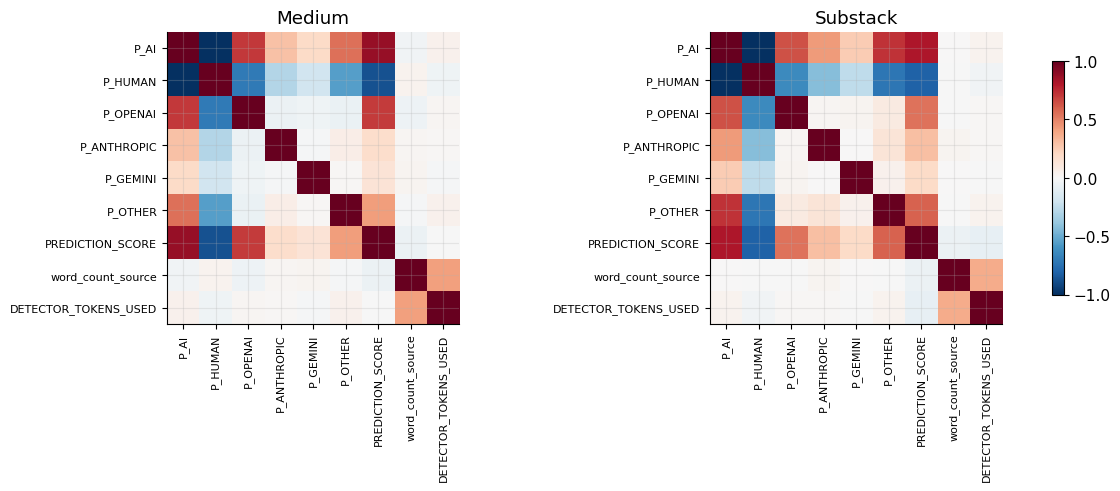

In [18]:
score_cols = ["P_AI", "P_HUMAN", "P_OPENAI", "P_ANTHROPIC", "P_GEMINI", "P_OTHER",
              "PREDICTION_SCORE", "word_count_source", "DETECTOR_TOKENS_USED"]

fig, axes = plt.subplots(1, 2, figsize=(12, 4.8), layout="constrained")
for ax, df, title in [(axes[0], m, "Medium"), (axes[1], s, "Substack")]:
    corr = df[score_cols].corr()
    im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
    ax.set_xticks(range(len(score_cols)))
    ax.set_yticks(range(len(score_cols)))
    ax.set_xticklabels(score_cols, rotation=90, fontsize=8)
    ax.set_yticklabels(score_cols, fontsize=8)
    ax.set_title(title)
fig.colorbar(im, ax=axes.ravel().tolist(), shrink=0.8)
plt.show()


## Takeaways

Both files are annual 50k samples with the same detector columns: exactly 50,000 posts per year and 350,000 unique posts per platform. Publication dates are represented as `YYYY-MM-DD`; all posts have valid dates and stay in the analysis. Monthly plots still group by year and month. September 2026 is partial through September 17.

Before ChatGPT the AI score is basically flat and near zero on both platforms. After December 2022 it rises on both, and a lot faster on Medium. By 2025–2026 most of the Medium sample clears a 0.5 cut; Substack is more like 30%. Stricter cuts (0.8, 0.95) lower the levels but keep the same shape.

The score is bimodal — near 0 or near 1 — so "mean P_AI" and "share above 0.5" tell almost the same story. Among posts that look AI, OpenAI and Other take most of the mass; Anthropic and Gemini are smaller.

Topic code 7 is the big bucket on both platforms. The AI rise shows up across most topic codes after 2022. Substack posts are longer on average. Length and AI flag are related, but the time pattern in the scores is the main result.

Things to keep in the write-up: these are detector probabilities, not labels we verified by hand; `PREDICTION` names an AI family even when `P_HUMAN` is high; topic codes have no legend in these files; all publication months are included in the monthly series; and this annual 50k draw is a different object from the capped creator-month Substack sample.
